In [1]:
from pynq.overlays.base import BaseOverlay
import xrfdc, numpy as np, matplotlib.pyplot as plt, time, os

base = BaseOverlay('base.bit'); base.init_rf_clks()
tx, blk = base.radio.transmitter.channel[0], base.radio.transmitter.channel[0].dac_block   # DAC_B
rx = base.radio.receiver.channel[1]                                                         # ADC_C
FS_RX, N = 4915.2e6 / 2, 2**15
os.makedirs('report_data', exist_ok=True)

def tx_tone(nco_mhz, gain=0.5):
    tx.control.enable = False
    blk.NyquistZone = 2                       # mix-mode
    blk.MixerSettings['Freq'] = nco_mhz       # image at 4915.2 + nco_mhz MHz
    tx.control.gain = gain
    tx.control.enable = True

rx.adc_block.NyquistZone = 1
rx.adc_block.MixerSettings['Freq'] = -784.8   # 5.7 GHz -> 0 Hz
rx.adc_block.UpdateEvent(xrfdc.EVENT_MIXER)

W = np.hanning(N)
F = np.fft.fftshift(np.fft.fftfreq(N, 1 / FS_RX))
def tone_level(f_expect_hz, n_avg=4):
    # tone power near f_expect [dBFS]: sum over the window's main lobe / 1.5,
    # so the result doesn't depend on where the tone falls between FFT bins
    near = np.flatnonzero(np.abs(F - f_expect_hz) < 1e6)
    p = 0.0
    for _ in range(n_avg):
        X2 = np.abs(np.fft.fftshift(np.fft.fft(rx.transfer(N) * W)) / W.sum()) ** 2
        k = near[np.argmax(X2[near])]
        p += X2[k - 3:k + 4].sum() / 1.5
    return 10 * np.log10(p / n_avg)


peak -62.4 dBFS; -3 dB band (DAC slope removed): 5665-5890 MHz


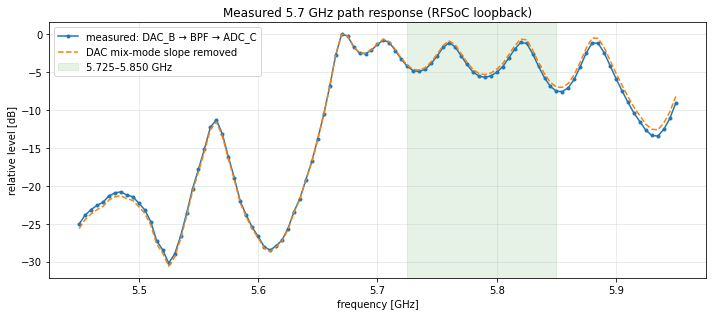

In [2]:
offsets = np.arange(-250, 251, 5)                     # MHz around 5.7 GHz
levels = []
for d in offsets:
    tx_tone(784.8 + d); time.sleep(0.05)
    levels.append(tone_level(d * 1e6))
levels = np.array(levels); tx_tone(784.8)
f_rf = 5700.0 + offsets
u = np.pi * f_rf / (2 * 4915.2)                       # DAC mix-mode response, known analytically
hmix_db = 20 * np.log10(np.sin(u) ** 2 / u); hmix_db -= hmix_db[offsets == 0]
np.savez('report_data/passband_sweep.npz', f_rf_mhz=f_rf, level_dbfs=levels, dac_mixmode_db=hmix_db)

rel = levels - hmix_db
inband = f_rf[rel >= rel.max() - 3]
print(f"peak {levels.max():.1f} dBFS; -3 dB band (DAC slope removed): {inband.min():.0f}-{inband.max():.0f} MHz")
plt.figure(figsize=(10, 4.5))
plt.plot(f_rf / 1e3, levels - levels.max(), 'o-', ms=3, label='measured: DAC_B → BPF → ADC_C')
plt.plot(f_rf / 1e3, rel - rel.max(), '--', label='DAC mix-mode slope removed')
plt.axvspan(5.725, 5.850, color='green', alpha=0.1, label='5.725–5.850 GHz')
plt.xlabel('frequency [GHz]'); plt.ylabel('relative level [dB]'); plt.grid(alpha=0.3); plt.legend()
plt.title('Measured 5.7 GHz path response (RFSoC loopback)'); plt.tight_layout()
plt.savefig('report_data/passband_sweep.png', dpi=150)


slope 0.655 dB/dB, max deviation from the fit 9.76 dB


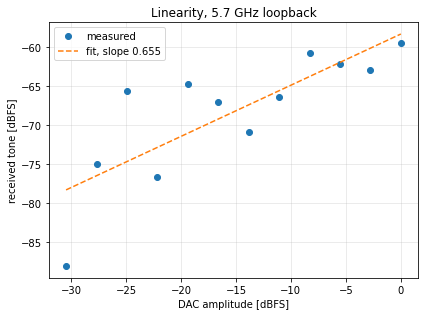

In [3]:
gains = np.geomspace(0.03, 1.0, 12)
lv = []
for g in gains:
    tx_tone(784.8, gain=g); time.sleep(0.05); lv.append(tone_level(0.0))
lv = np.array(lv); x = 20 * np.log10(gains); tx_tone(784.8)
slope, icpt = np.polyfit(x, lv, 1)
np.savez('report_data/linearity.npz', gain_db=x, level_dbfs=lv)
print(f"slope {slope:.3f} dB/dB, max deviation from the fit {np.max(np.abs(lv - (slope * x + icpt))):.2f} dB")
plt.figure(figsize=(6, 4.5))
plt.plot(x, lv, 'o', label='measured'); plt.plot(x, slope * x + icpt, '--', label=f'fit, slope {slope:.3f}')
plt.xlabel('DAC amplitude [dBFS]'); plt.ylabel('received tone [dBFS]'); plt.grid(alpha=0.3); plt.legend()
plt.title('Linearity, 5.7 GHz loopback'); plt.tight_layout(); plt.savefig('report_data/linearity.png', dpi=150)

phase: mean 118.2 deg, std 0.65 deg, total drift 0.85 deg
residual frequency: -36312733.6 ± 8223232.8 Hz


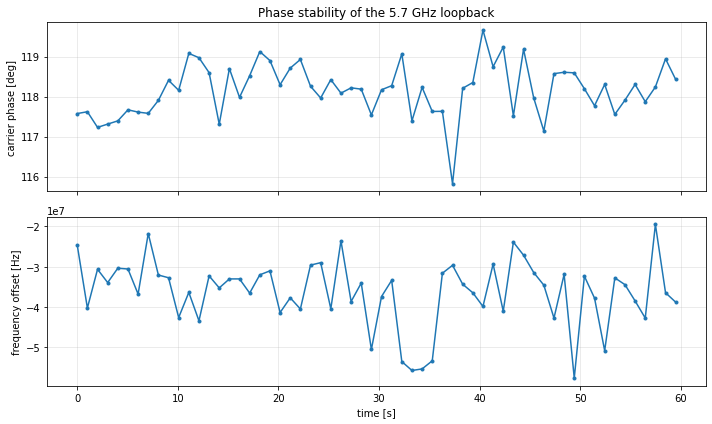

In [4]:
tx_tone(784.8)
t0, ts, ph, fo = time.time(), [], [], []
while time.time() - t0 < 60:                          # one capture per second for 60 s
    x = rx.transfer(N)
    ts.append(time.time() - t0)
    ph.append(np.angle(np.mean(x)))                   # carrier phase (the tone sits at 0 Hz)
    fo.append(np.angle(np.sum(x[1:] * np.conj(x[:-1]))) * FS_RX / (2 * np.pi))   # residual frequency
    time.sleep(1.0)
ph_deg = np.degrees(np.unwrap(ph)); fo = np.array(fo)
np.savez('report_data/phase_stability.npz', t_s=ts, phase_deg=ph_deg, freq_offset_hz=fo)
print(f"phase: mean {ph_deg.mean():.1f} deg, std {ph_deg.std():.2f} deg, total drift {ph_deg[-1] - ph_deg[0]:.2f} deg")
print(f"residual frequency: {fo.mean():+.1f} ± {fo.std():.1f} Hz")
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax[0].plot(ts, ph_deg, 'o-', ms=3); ax[0].set(ylabel='carrier phase [deg]', title='Phase stability of the 5.7 GHz loopback')
ax[1].plot(ts, fo, 'o-', ms=3); ax[1].set(xlabel='time [s]', ylabel='frequency offset [Hz]')
for a in ax: a.grid(alpha=0.3)
fig.tight_layout(); fig.savefig('report_data/phase_stability.png', dpi=150)


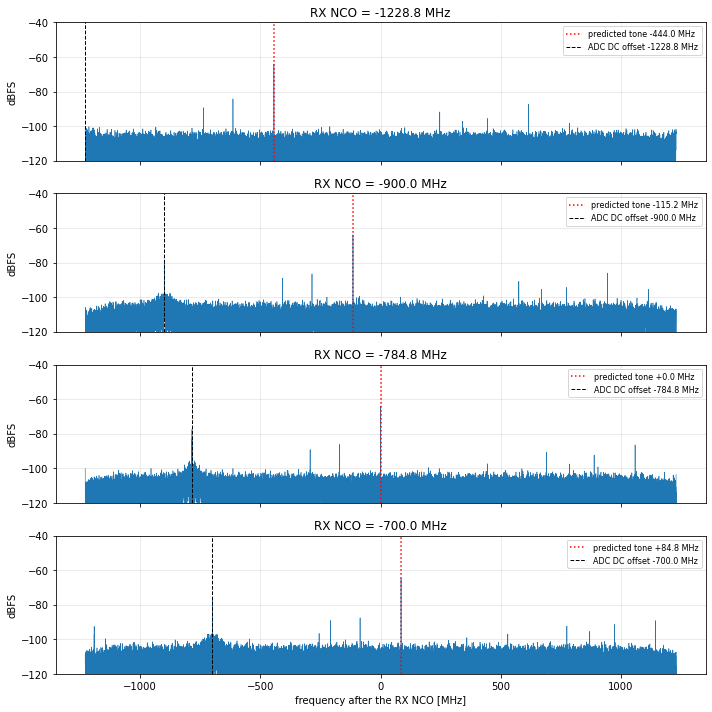

In [5]:
tx_tone(784.8)                                       # 5.7 GHz, fixed
nco_list = [-1228.8, -900.0, -784.8, -700.0]         # MHz
wrap = lambda f: (f + 1228.8) % 2457.6 - 1228.8      # fold into the ±1228.8 MHz output band
fig, axs = plt.subplots(len(nco_list), 1, figsize=(10, 10), sharex=True)
spectra = []
for ax, nco in zip(axs, nco_list):
    rx.adc_block.MixerSettings['Freq'] = nco
    rx.adc_block.UpdateEvent(xrfdc.EVENT_MIXER)
    time.sleep(0.05)
    P = 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(rx.transfer(N) * W))) / W.sum() + 1e-15)
    spectra.append(P)
    f_tone = wrap(784.8 + nco)
    ax.plot(F / 1e6, P, lw=0.6)
    ax.axvline(f_tone, color='r', ls=':', lw=1.5, label=f'predicted tone {f_tone:+.1f} MHz')
    ax.axvline(wrap(nco), color='k', ls='--', lw=1, label=f'ADC DC offset {wrap(nco):+.1f} MHz')
    ax.set(ylabel='dBFS', ylim=(-120, -40), title=f'RX NCO = {nco:.1f} MHz')
    ax.legend(fontsize=8, loc='upper right'); ax.grid(alpha=0.3)
axs[-1].set_xlabel('frequency after the RX NCO [MHz]')
fig.tight_layout(); fig.savefig('report_data/rx_nco_tuning.png', dpi=150)
np.savez('report_data/rx_nco_tuning.npz', f_hz=F, nco_mhz=nco_list, spectra_dbfs=np.array(spectra))

rx.adc_block.MixerSettings['Freq'] = -784.8           # back to 5.7 GHz -> 0 Hz
rx.adc_block.UpdateEvent(xrfdc.EVENT_MIXER)


In [6]:
for ch in base.radio.transmitter.channel:            # DAC_B (channel 0) and DAC_A (channel 1)
    ch.control.enable = False                         # output zeros
    ch.control.gain = 0
    ch.dac_tile.ShutDown()                            # power down the DAC tile
print("DAC outputs disabled and tiles shut down")


DAC outputs disabled and tiles shut down


In [7]:
for i, name in [(1, 'ADC_C (from DAC_B)'), (0, 'ADC_D (from DAC_A)')]:
    x = base.radio.receiver.channel[i].transfer(N)
    P = 20 * np.log10(np.abs(np.fft.fftshift(np.fft.fft(x * W))) / W.sum() + 1e-15)
    print(f"{name}: strongest line {P.max():.1f} dBFS (only noise and spurs: roughly -70 dBFS or below)")

ADC_C (from DAC_B): strongest line -79.8 dBFS (only noise and spurs: roughly -70 dBFS or below)
ADC_D (from DAC_A): strongest line -84.2 dBFS (only noise and spurs: roughly -70 dBFS or below)
